In [1]:
import pandas as pd
from sklearn.preprocessing import StandardScaler

# 1. Load the dataset (fixed the double .parquet typo)
df = pd.read_parquet('../data/network_intrusion_clustering.parquet')

# 2. Drop Label — clustering is unsupervised, Label used only for evaluation
# Notice we are using 'df' here, not 'df_clustering'
X = df.drop(columns=['Label'])
y = df['Label']  # saved for post-hoc interpretation

# 3. Standardize features (zero mean, unit variance)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(f"Feature matrix shape : {X_scaled.shape}")
print(f"Label series shape   : {y.shape}")
print("All scaled with standart scaler ")

Feature matrix shape : (20206, 25)
Label series shape   : (20206,)
All scaled with standart scaler 


In [2]:
import json

# 1. Load the label mapping JSON file
# (Make sure the path matches your folder structure)
with open('../data/label_mapping.json', 'r') as f:
    label_mapping = json.load(f)

# 2. Reverse the dictionary so numbers are the keys
# JSON saves keys as strings, so we convert the value 'v' to an integer
inverse_mapping = {int(v): k for k, v in label_mapping.items()}

# 3. Create a permanent 'Label_Name' column for easy evaluation later
df['Label_Name'] = df['Label'].map(inverse_mapping)

print("Label mapping loaded!")

Label mapping loaded!


## K-Means

k= 2 | Inertia:     425190.8 | Silhouette: 0.5174 | Davies-Bouldin: 1.6643
k= 3 | Inertia:     387101.1 | Silhouette: 0.5051 | Davies-Bouldin: 1.3834
k= 4 | Inertia:     359830.9 | Silhouette: 0.4903 | Davies-Bouldin: 1.3774
k= 5 | Inertia:     326754.8 | Silhouette: 0.4332 | Davies-Bouldin: 1.4219
k= 6 | Inertia:     312265.2 | Silhouette: 0.4662 | Davies-Bouldin: 1.1617
k= 7 | Inertia:     284007.3 | Silhouette: 0.4547 | Davies-Bouldin: 1.2459
k= 8 | Inertia:     262628.1 | Silhouette: 0.4277 | Davies-Bouldin: 1.0294
k= 9 | Inertia:     243735.6 | Silhouette: 0.4681 | Davies-Bouldin: 1.0342
k=10 | Inertia:     223509.7 | Silhouette: 0.4948 | Davies-Bouldin: 0.9627
k=11 | Inertia:     209493.1 | Silhouette: 0.4433 | Davies-Bouldin: 1.0470


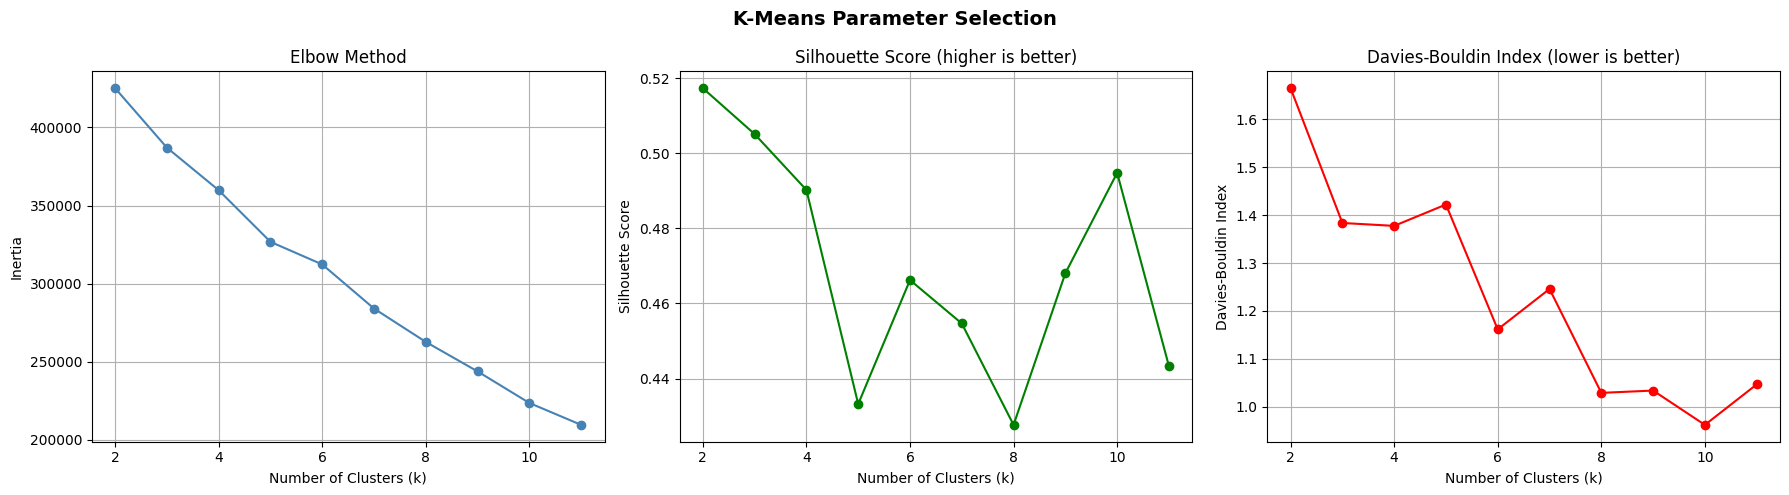


  Best k selected    : 2
   Silhouette Score  : 0.5174
   Davies-Bouldin    : 1.6643
   ARI               : 0.2443  (1.0 = perfect, 0 = random)
   NMI               : 0.1556  (1.0 = perfect, 0 = no mutual info)

 K-Means complete. Cluster labels saved to df.


In [3]:
# =============================================================
# K-MEANS CLUSTERING
# =============================================================
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score, normalized_mutual_info_score

k_range = range(2, 12)

inertias          = []
silhouette_scores = []
db_scores         = []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)

    inertias.append(km.inertia_)
    silhouette_scores.append(silhouette_score(X_scaled, labels))
    db_scores.append(davies_bouldin_score(X_scaled, labels))

    print(f"k={k:2d} | Inertia: {km.inertia_:>12.1f} | "
          f"Silhouette: {silhouette_scores[-1]:.4f} | "
          f"Davies-Bouldin: {db_scores[-1]:.4f}")

# -------------------------------------------------------------
# Plots
# -------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(k_range, inertias, marker='o', color='steelblue')
axes[0].set_title('Elbow Method')
axes[0].set_xlabel('Number of Clusters (k)')
axes[0].set_ylabel('Inertia')
axes[0].grid(True)

axes[1].plot(k_range, silhouette_scores, marker='o', color='green')
axes[1].set_title('Silhouette Score (higher is better)')
axes[1].set_xlabel('Number of Clusters (k)')
axes[1].set_ylabel('Silhouette Score')
axes[1].grid(True)

axes[2].plot(k_range, db_scores, marker='o', color='red')
axes[2].set_title('Davies-Bouldin Index (lower is better)')
axes[2].set_xlabel('Number of Clusters (k)')
axes[2].set_ylabel('Davies-Bouldin Index')
axes[2].grid(True)

plt.suptitle('K-Means Parameter Selection', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# -------------------------------------------------------------
# Best k & Final Model
# -------------------------------------------------------------
best_k = silhouette_scores.index(max(silhouette_scores)) + 2

km_best = KMeans(n_clusters=best_k, random_state=42, n_init=10)
kmeans_labels = km_best.fit_predict(X_scaled)

# Save labels back to df
df['KMeans_Cluster'] = kmeans_labels

# -------------------------------------------------------------
# Evaluation vs Ground Truth (Label)
# -------------------------------------------------------------
ari = adjusted_rand_score(y, kmeans_labels)
nmi = normalized_mutual_info_score(y, kmeans_labels)

print(f"\n  Best k selected    : {best_k}")
print(f"   Silhouette Score  : {max(silhouette_scores):.4f}")
print(f"   Davies-Bouldin    : {db_scores[best_k - 2]:.4f}")
print(f"   ARI               : {ari:.4f}  (1.0 = perfect, 0 = random)")
print(f"   NMI               : {nmi:.4f}  (1.0 = perfect, 0 = no mutual info)")

print("\n K-Means complete. Cluster labels saved to df.")

In [4]:
# Automated search selected k=2, driven by class imbalance (83% BENIGN).
# Overriding to k=10: lowest Davies-Bouldin (0.9627) + ~14 traffic categories in dataset.
best_k = 6
km_best = KMeans(n_clusters=best_k, random_state=42, n_init=10)
kmeans_labels = km_best.fit_predict(X_scaled)
df['KMeans_Cluster'] = kmeans_labels

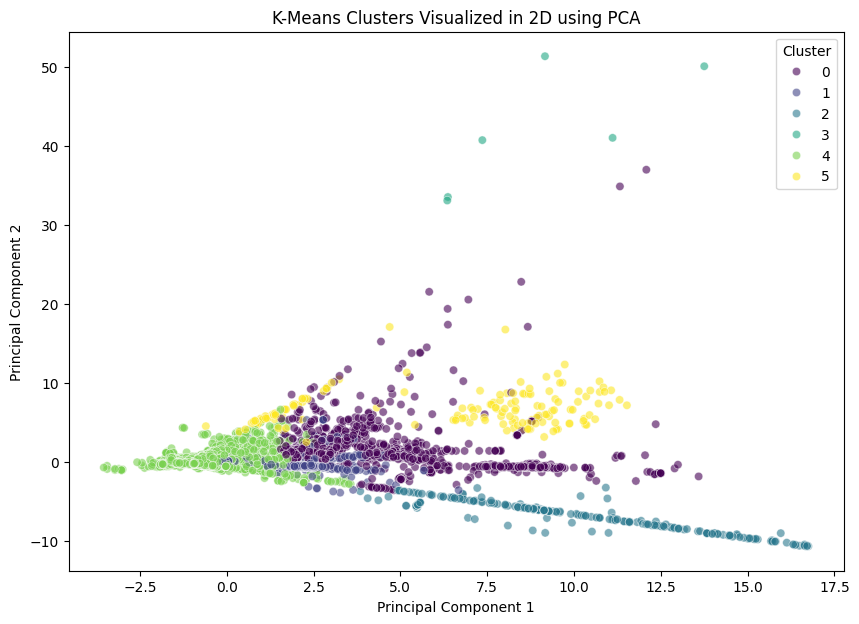

In [5]:
from sklearn.decomposition import PCA
import seaborn as sns

# Squash the 25 dimensions down to 2 dimensions (Principal Components)
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Plot the PCA results, coloring the dots by their K-Means cluster
plt.figure(figsize=(10, 7))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=df['KMeans_Cluster'], palette='viridis', alpha=0.6)
plt.title('K-Means Clusters Visualized in 2D using PCA')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(title='Cluster')
plt.show()

In [6]:
# Create a table comparing the true label names to the K-Means clusters
kmeans_analysis = pd.crosstab(
    index=df['Label_Name'], 
    columns=df['KMeans_Cluster'], 
    margins=True
)

print("K-Means Cluster Distribution vs. True Labels:")
display(kmeans_analysis)

K-Means Cluster Distribution vs. True Labels:


KMeans_Cluster,0,1,2,3,4,5,All
Label_Name,,,,,,,
BENIGN,1408,35,223,0,14915,158,16739
Bot,0,0,0,0,16,0,16
DDoS,0,351,0,0,673,0,1024
DoS GoldenEye,1,26,12,0,43,0,82
DoS Hulk,350,770,1,0,260,0,1381
DoS Slowhttptest,12,17,0,0,12,1,42
DoS slowloris,17,0,10,0,16,0,43
FTP-Patator,0,0,0,0,47,0,47
Heartbleed,6,1,0,0,0,0,7


## Hierarchical

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score

# 2. Evaluate Linkages and k
k_range = range(2, 11)
linkages = ['ward', 'complete', 'average', 'single']

results = []

print("Evaluating Hierarchical Clustering...\n")
print(f"{'Linkage':<10} | {'k':<3} | {'Silhouette':<12} | {'Davies-Bouldin'}")
print("-" * 50)

# After the loop, before finding best_idx
# Add cluster balance check — compute smallest cluster size as % of data
def min_cluster_pct(X, labels):
    unique, counts = np.unique(labels, return_counts=True)
    return counts.min() / len(labels) * 100

for linkage in linkages:
    for k in k_range:
        # Ward requires euclidean distance; the others can use different metrics, 
        # but sticking to euclidean keeps the comparison standardized.
        hc = AgglomerativeClustering(n_clusters=k, metric='euclidean', linkage=linkage)
        labels = hc.fit_predict(X_scaled)
        
        # Calculate internal metrics
        sil_score = silhouette_score(X_scaled, labels)
        db_score = davies_bouldin_score(X_scaled, labels)
        min_pct   = min_cluster_pct(X_scaled, labels)
        
        results.append({
            'linkage': linkage,
            'k': k,
            'silhouette': sil_score,
            'davies_bouldin': db_score,
            'min_cluster_pct': min_pct 
        })
        
        print(f"{linkage:<10} | {k:<3} | {sil_score:<12.4f} | {db_score:.4f}")
    print("-" * 40)

# Convert to DataFrame for easy querying
results_df = pd.DataFrame(results)

Evaluating Hierarchical Clustering...

Linkage    | k   | Silhouette   | Davies-Bouldin
--------------------------------------------------
ward       | 2   | 0.5041       | 1.7373
ward       | 3   | 0.4981       | 1.4779
ward       | 4   | 0.4961       | 1.1567
ward       | 5   | 0.4886       | 1.0964
ward       | 6   | 0.4809       | 1.0095
ward       | 7   | 0.4174       | 1.0700
ward       | 8   | 0.4470       | 1.0531
ward       | 9   | 0.4527       | 1.0310
ward       | 10  | 0.4567       | 0.9865
----------------------------------------
complete   | 2   | 0.9394       | 0.2093
complete   | 3   | 0.9234       | 0.3945
complete   | 4   | 0.9182       | 0.3562
complete   | 5   | 0.7481       | 0.6760
complete   | 6   | 0.7233       | 0.5193
complete   | 7   | 0.7248       | 0.5197
complete   | 8   | 0.7261       | 0.5328
complete   | 9   | 0.7261       | 0.5187
complete   | 10  | 0.7261       | 0.4837
----------------------------------------
average    | 2   | 0.9394       | 0.2093


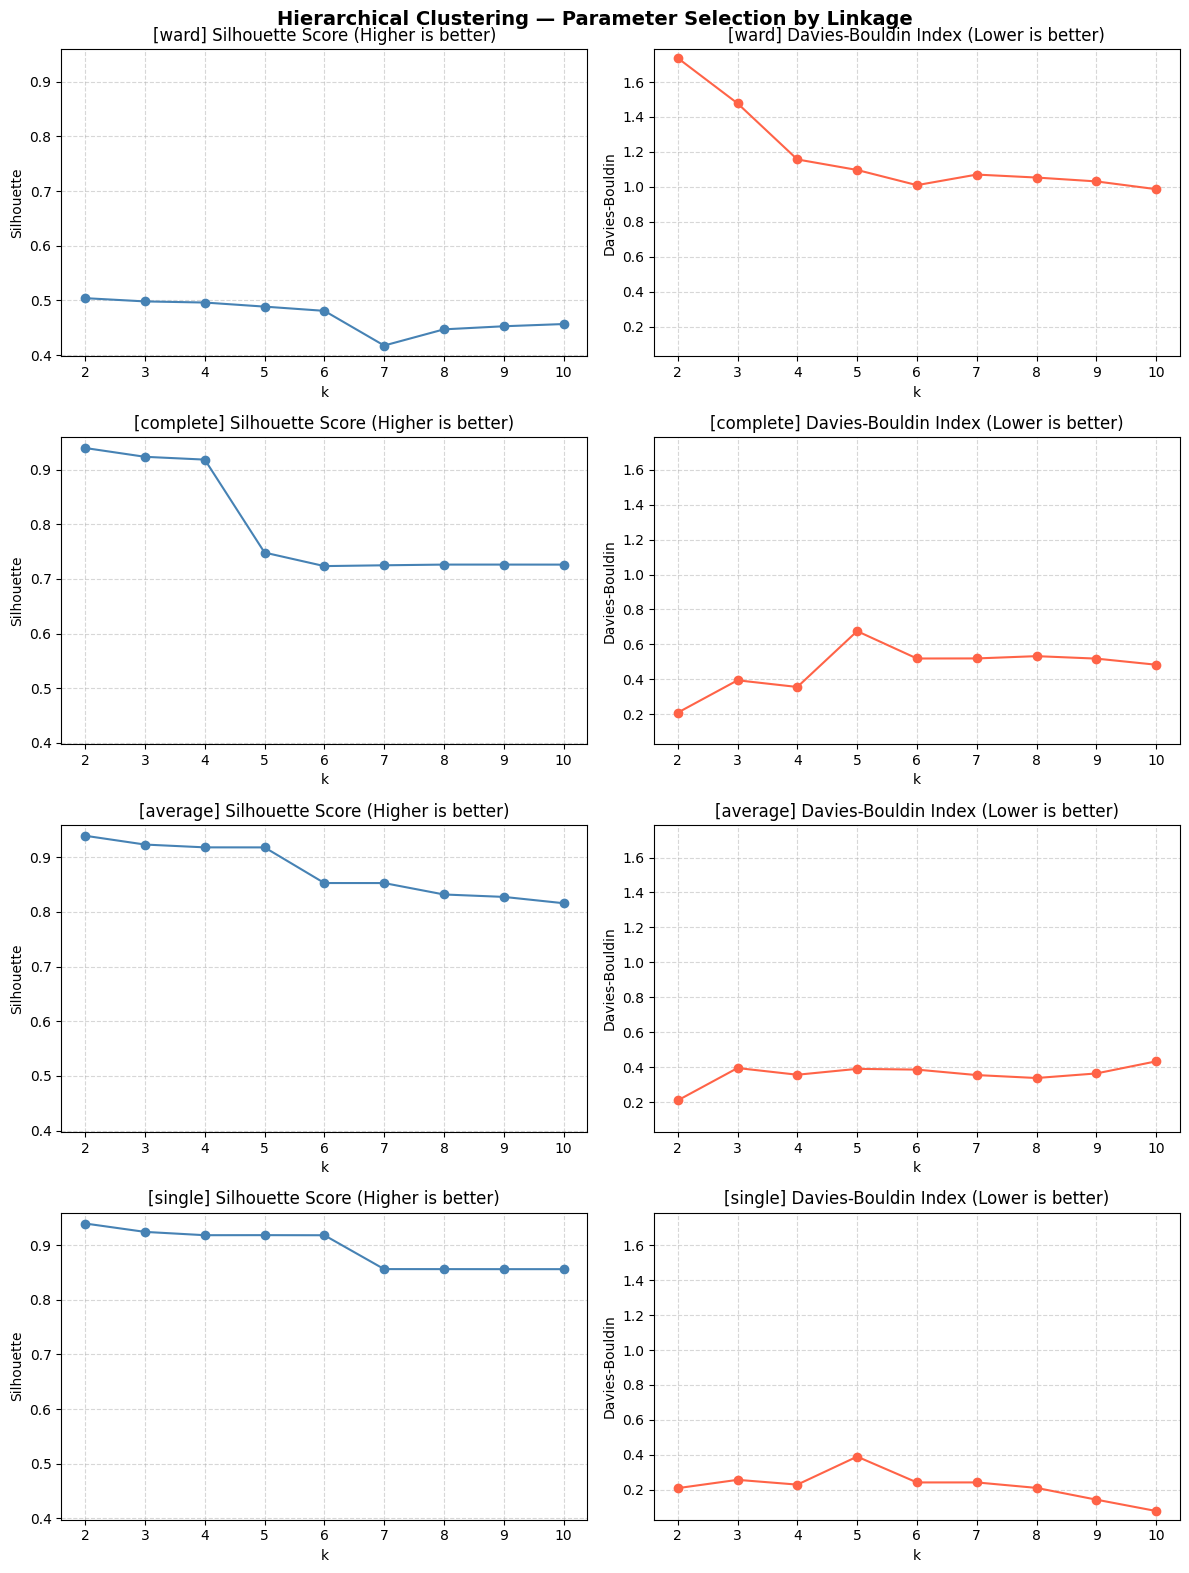

In [4]:
sil_min, sil_max = results_df['silhouette'].min(), results_df['silhouette'].max()
db_min,  db_max  = results_df['davies_bouldin'].min(), results_df['davies_bouldin'].max()

fig, axes = plt.subplots(len(linkages), 2, figsize=(12, 4 * len(linkages)))

for row, linkage in enumerate(linkages):
    df_link = results_df[results_df['linkage'] == linkage]
    
    axes[row, 0].plot(df_link['k'], df_link['silhouette'], marker='o', color='steelblue')
    axes[row, 0].set_title(f'[{linkage}] Silhouette Score (Higher is better)')
    axes[row, 0].set_xlabel('k')
    axes[row, 0].set_ylabel('Silhouette')
    axes[row, 0].set_xticks(df_link['k'])
    axes[row, 0].set_ylim(sil_min - 0.02, sil_max + 0.02)
    axes[row, 0].grid(True, linestyle='--', alpha=0.5)

    axes[row, 1].plot(df_link['k'], df_link['davies_bouldin'], marker='o', color='tomato')
    axes[row, 1].set_title(f'[{linkage}] Davies-Bouldin Index (Lower is better)')
    axes[row, 1].set_xlabel('k')
    axes[row, 1].set_ylabel('Davies-Bouldin')
    axes[row, 1].set_xticks(df_link['k'])
    axes[row, 1].set_ylim(db_min - 0.05, db_max + 0.05)
    axes[row, 1].grid(True, linestyle='--', alpha=0.5)

plt.suptitle('Hierarchical Clustering — Parameter Selection by Linkage', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [12]:
# Only consider results where every cluster holds at least 5% of the data
valid_df = results_df[results_df['min_cluster_pct'] >= 5.0]

if valid_df.empty:
    print("No configuration met the min_cluster_pct >= 5% threshold (likely due to class imbalance). Falling back to all results.")
    valid_df = results_df

best_idx = valid_df['silhouette'].idxmax()

# -------------------------------------------------------------
# 3. Find Best Parameters & Save Final Model
# -------------------------------------------------------------

# Automatically find the parameters that yielded the highest Silhouette score
best_k = int(results_df.loc[best_idx, 'k'])
best_linkage = results_df.loc[best_idx, 'linkage']
best_silhouette = results_df.loc[best_idx, 'silhouette']

#override best k and linkage
best_k = 6
best_linkage = 'ward'

print("\n" + "=" * 40)
print("BEST MODEL SELECTED")
print("=" * 40)
print(f" Best Linkage : {best_linkage}")
print(f" Best k       : {best_k}")
print(f" Silhouette   : {best_silhouette:.4f}")

# Run the final model with the absolute best parameters
hc_best = AgglomerativeClustering(n_clusters=best_k, metric='euclidean', linkage=best_linkage)
hc_best_labels = hc_best.fit_predict(X_scaled)

# Save the labels back to the sampled dataframe for later use (like PCA)
df['HC_Cluster'] = hc_best_labels

print("\nHierarchical Clustering complete. Best labels saved to df.")


BEST MODEL SELECTED
 Best Linkage : ward
 Best k       : 6
 Silhouette   : 0.5041

Hierarchical Clustering complete. Best labels saved to df.


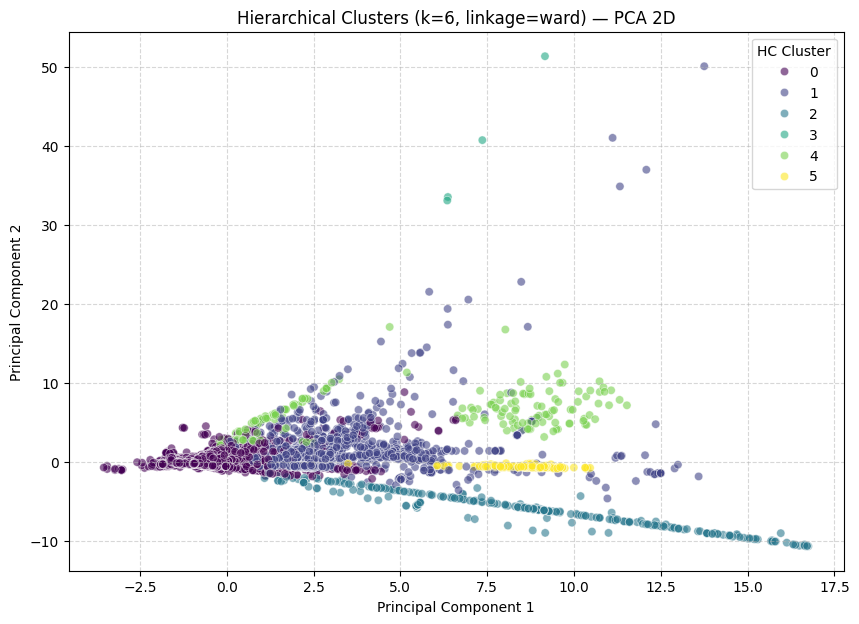

In [13]:
from sklearn.decomposition import PCA
import seaborn as sns
import matplotlib.pyplot as plt

# No need to re-fit — hc_best_labels is already computed above
# Just reduce dimensions for plotting
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(10, 7))
sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=df['HC_Cluster'],
    palette='viridis',
    alpha=0.6
)
plt.title(f'Hierarchical Clusters (k={best_k}, linkage={best_linkage}) — PCA 2D')  # ← dynamic title
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(title='HC Cluster')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [14]:
hc_analysis = pd.crosstab(
    index=df['Label_Name'],
    columns=df['HC_Cluster'],
    margins=True
)

print("Hierarchical Cluster Distribution vs. True Label Names:")   # ← removed "(Sample Data)"
display(hc_analysis)

Hierarchical Cluster Distribution vs. True Label Names:


HC_Cluster,0,1,2,3,4,5,All
Label_Name,,,,,,,
BENIGN,14709,1554,271,0,205,0,16739
Bot,16,0,0,0,0,0,16
DDoS,857,167,0,0,0,0,1024
DoS GoldenEye,60,2,20,0,0,0,82
DoS Hulk,313,721,0,0,0,347,1381
DoS Slowhttptest,13,29,0,0,0,0,42
DoS slowloris,16,17,10,0,0,0,43
FTP-Patator,47,0,0,0,0,0,47
Heartbleed,0,7,0,0,0,0,7


## DBSCAN

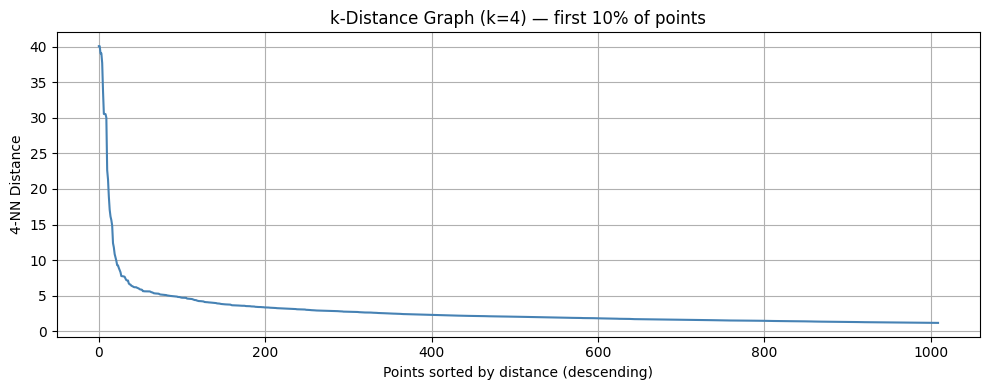

In [15]:
from sklearn.neighbors import NearestNeighbors
k_nn = 4
nbrs = NearestNeighbors(n_neighbors=k_nn).fit(X_scaled)
distances, _ = nbrs.kneighbors(X_scaled)
k_distances = np.sort(distances[:, -1])[::-1]

# Only plot the first 10% of points — elbow always appears here
cutoff = int(len(k_distances) * 0.05)

plt.figure(figsize=(10, 4))
plt.plot(k_distances[:cutoff], color='steelblue')
plt.title(f'k-Distance Graph (k={k_nn}) — first 10% of points')
plt.xlabel('Points sorted by distance (descending)')
plt.ylabel(f'{k_nn}-NN Distance')
plt.grid(True)
plt.tight_layout()
plt.show()

In [16]:
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score
import itertools

# 2. Grid Search to find the best combination of eps and min_samples
# Adjust the lists below based on what you saw in the K-distance plot!
eps_grid = [ 0.5, 0.8, 1, 1.3, 1.5, 2, 2.5] 
min_samples_grid = [5, 10, 15, 20, 50, 100]

best_sil_score = -1
best_eps = None
best_min_samples = None

print("Starting Grid Search for DBSCAN...\n")

for eps, min_samples in itertools.product(eps_grid, min_samples_grid):
    dbscan_temp = DBSCAN(eps=eps, min_samples=min_samples)
    labels_temp = dbscan_temp.fit_predict(X_scaled)
    
    # Calculate number of clusters (excluding noise which is -1)
    n_clusters_temp = len(set(labels_temp)) - (1 if -1 in labels_temp else 0)
    
    # Silhouette score requires at least 2 clusters
    if n_clusters_temp > 1:
        sil_score = silhouette_score(X_scaled, labels_temp)
        print(f"eps={eps:<4} | min_samples={min_samples:<2} --> Clusters: {n_clusters_temp:<3} | Silhouette: {sil_score:.4f}")
        
        # Track the best score
        if sil_score > best_sil_score:
            best_sil_score = sil_score
            best_eps = eps
            best_min_samples = min_samples

print("\n" + "="*50)
if best_eps is not None:
    print(f"BEST PARAMETERS: eps = {best_eps}, min_samples = {best_min_samples}")
    print(f"BEST SILHOUETTE SCORE: {best_sil_score:.4f}")
else:
    print("No combination produced more than 1 cluster. Try adjusting your eps_grid.")

Starting Grid Search for DBSCAN...

eps=0.5  | min_samples=5  --> Clusters: 144 | Silhouette: 0.2767
eps=0.5  | min_samples=10 --> Clusters: 81  | Silhouette: 0.2810
eps=0.5  | min_samples=15 --> Clusters: 56  | Silhouette: 0.2834
eps=0.5  | min_samples=20 --> Clusters: 47  | Silhouette: 0.2680
eps=0.5  | min_samples=50 --> Clusters: 30  | Silhouette: 0.4021
eps=0.5  | min_samples=100 --> Clusters: 20  | Silhouette: 0.3044
eps=0.8  | min_samples=5  --> Clusters: 79  | Silhouette: 0.2985
eps=0.8  | min_samples=10 --> Clusters: 49  | Silhouette: 0.4272
eps=0.8  | min_samples=15 --> Clusters: 41  | Silhouette: 0.4527
eps=0.8  | min_samples=20 --> Clusters: 32  | Silhouette: 0.4466
eps=0.8  | min_samples=50 --> Clusters: 23  | Silhouette: 0.4231
eps=0.8  | min_samples=100 --> Clusters: 14  | Silhouette: 0.4028
eps=1    | min_samples=5  --> Clusters: 71  | Silhouette: 0.2928
eps=1    | min_samples=10 --> Clusters: 37  | Silhouette: 0.3551
eps=1    | min_samples=15 --> Clusters: 33  | Silhou

In [17]:
# 3. Fit the final DBSCAN model using the best parameters from Grid Search

#best_eps = 0.8
#best_min_samples = 100
print(f"Fitting final DBSCAN with eps={best_eps}, min_samples={best_min_samples}...\n")
dbscan = DBSCAN(eps=best_eps, min_samples=best_min_samples)
dbscan_labels = dbscan.fit_predict(X_scaled)

# Save cluster labels to DataFrame
df['DBSCAN_Cluster'] = dbscan_labels

# Calculate final statistics
n_clusters = len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)
n_noise = list(dbscan_labels).count(-1)

print(f"Final Estimated number of clusters : {n_clusters}")
print(f"Final Estimated number of noise pts : {n_noise}\n")

if n_clusters > 1:
    final_sil_score = silhouette_score(X_scaled, dbscan_labels)
    final_db_score = davies_bouldin_score(X_scaled, dbscan_labels)
    print(f"Final Silhouette Score     : {final_sil_score:.4f}")
    print(f"Final Davies-Bouldin Score : {final_db_score:.4f}")

Fitting final DBSCAN with eps=1, min_samples=50...

Final Estimated number of clusters : 17
Final Estimated number of noise pts : 2708

Final Silhouette Score     : 0.4560
Final Davies-Bouldin Score : 1.7454


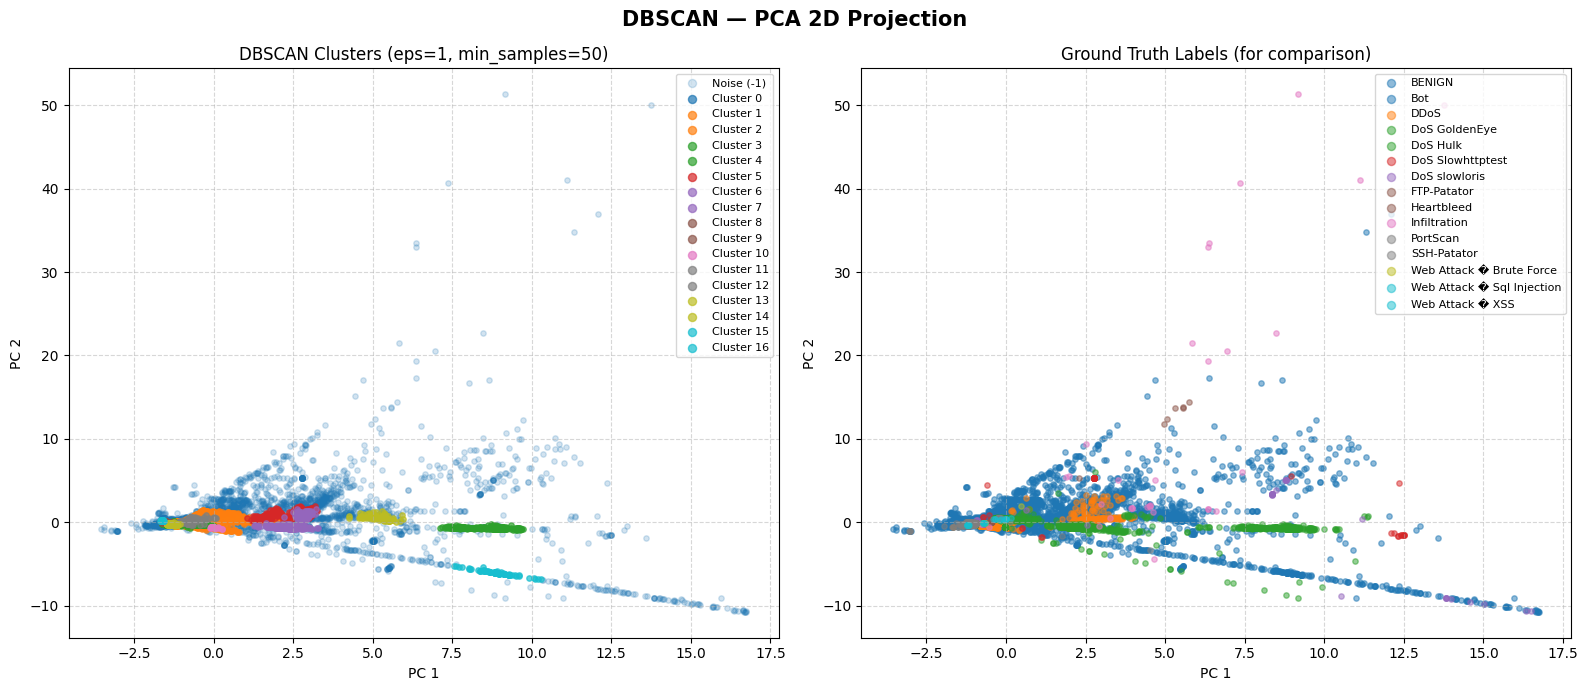

In [18]:
from sklearn.decomposition import PCA

# 4. Reduce dimensions and Plot
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# — DBSCAN Clusters
unique_dbscan = sorted(set(dbscan_labels))
colors_db = plt.cm.tab10(np.linspace(0, 1, len(unique_dbscan)))

for lbl, col in zip(unique_dbscan, colors_db):
    mask = dbscan_labels == lbl
    # Make noise points faint and clusters distinct
    alpha_val = 0.2 if lbl == -1 else 0.7
    label_name = 'Noise (-1)' if lbl == -1 else f'Cluster {lbl}'
    
    axes[0].scatter(X_pca[mask, 0], X_pca[mask, 1],
                    c=[col], label=label_name, s=15, alpha=alpha_val)

axes[0].set_title(f'DBSCAN Clusters (eps={best_eps}, min_samples={best_min_samples})')
axes[0].set_xlabel('PC 1')
axes[0].set_ylabel('PC 2')
axes[0].legend(loc='upper right', fontsize=8, markerscale=1.5)
axes[0].grid(True, linestyle='--', alpha=0.5)

# — Ground truth labels for comparison
unique_true = sorted(set(df["Label_Name"]))
colors_gt = plt.cm.tab10(np.linspace(0, 1, len(unique_true)))

for lbl, col in zip(unique_true, colors_gt):
    mask = np.array(df["Label_Name"]) == lbl
    axes[1].scatter(X_pca[mask, 0], X_pca[mask, 1],
                    c=[col], label=str(lbl), s=15, alpha=0.5)

axes[1].set_title('Ground Truth Labels (for comparison)')
axes[1].set_xlabel('PC 1')
axes[1].set_ylabel('PC 2')
axes[1].legend(loc='upper right', fontsize=8, markerscale=1.5)
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.suptitle('DBSCAN — PCA 2D Projection', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

In [ ]:
hc_analysis = pd.crosstab(
    index=df['Label_Name'],
    columns=df['DBSCAN_Cluster'],
    margins=True
)

print("DBSCAN Cluster Distribution vs. True Label Names:")
with pd.option_context('display.max_rows', None, 'display.max_columns', None):
    display(hc_analysis)

Hierarchical Cluster Distribution vs. True Label Names:


DBSCAN_Cluster,-1,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,All
Label_Name,,,,,,,,,,,,,,,,,,,
BENIGN,2263,590,10108,507,0,1386,390,0,227,216,108,104,90,157,368,94,79,52,16739
Bot,1,0,9,0,0,6,0,0,0,0,0,0,0,0,0,0,0,0,16
DDoS,162,0,851,0,0,0,0,11,0,0,0,0,0,0,0,0,0,0,1024
DoS GoldenEye,43,0,39,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,82
DoS Hulk,104,0,192,0,319,1,0,695,0,0,0,69,0,0,1,0,0,0,1381
DoS Slowhttptest,38,0,0,0,0,2,0,0,0,0,0,0,2,0,0,0,0,0,42
DoS slowloris,31,1,11,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,43
FTP-Patator,0,17,30,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,47
Heartbleed,7,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,7


## final comparison

In [ ]:
import pandas as pd
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score, homogeneity_score

algorithms = {
    'K-Means': df['KMeans_Cluster'],
    'Hierarchical': df['HC_Cluster'],
    'DBSCAN': df['DBSCAN_Cluster']
}

comparison_data = []

for name, preds in algorithms.items():
    # Υπολογισμός μετρικών σύγκρισης με τα αληθινά Labels
    ari = adjusted_rand_score(y, preds)
    nmi = normalized_mutual_info_score(y, preds)
    homogeneity = homogeneity_score(y, preds)
    
    comparison_data.append({
        'Algorithm': name,
        'Adjusted Rand Index (ARI)': ari,
        'Normalized Mutual Info (NMI)': nmi,
        'Homogeneity': homogeneity
    })

# Δημιουργία του τελικού πίνακα
comparison_df = pd.DataFrame(comparison_data)

print("--- Final algorithm comparison to truth label ---")
display(comparison_df)

--- Τελική Σύγκριση Αλγορίθμων ως προς τη μεταβλητή Label ---


,Algorithm,Adjusted Rand Index (ARI),Normalized Mutual Info (NMI),Homogeneity
0,K-Means,0.319703,0.251393,0.237195
1,Hierarchical,0.217726,0.138084,0.112723
2,DBSCAN,0.043858,0.188782,0.304787
